In [14]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [15]:
# Load VMT, gas price data, and real GDP data
vmt = pd.read_excel("Vehicle Miles Traveled (United States).xlsx",
                    sheet_name="Monthly")
gas = pd.read_excel("US Regular Convetional Gas Price.xlsx",
                    sheet_name="Monthly")
gdp = pd.read_excel("RealGDP.xlsx",
                    sheet_name="Quarterly")

# Make sure dates are datetime
vmt["observation_date"] = pd.to_datetime(vmt["observation_date"])
gas["observation_date"] = pd.to_datetime(gas["observation_date"])
gdp["observation_date"] = pd.to_datetime(gdp["observation_date"])

# Convert quarterly GDP to **monthly, month-start**
gdp_m = (
    gdp
    .set_index("observation_date")
    .resample("MS")      # <-- THIS is the important change
    .ffill()
    .reset_index()
)

# Merge VMT and gas price first (both monthly, same date format)
df = pd.merge(vmt, gas, on="observation_date", how="inner")

# Merge in monthly GDP
df = pd.merge(df, gdp_m, on="observation_date", how="inner")

# Restrict sample
start_date = "2000-01-01"
end_date   = "2019-12-01"

df = df[(df["observation_date"] >= start_date) &
        (df["observation_date"] <= end_date)].copy()

print(df.shape)
print(df.head())
print(df.tail())

(240, 4)
  observation_date     VMT  GPRICE       RGDP
0       2000-01-01  227235   1.279  13878.147
1       2000-02-01  228727   1.371  13878.147
2       2000-03-01  230237   1.498  13878.147
3       2000-04-01  229068   1.437  14130.908
4       2000-05-01  229651   1.456  14130.908
    observation_date     VMT  GPRICE       RGDP
235       2019-08-01  276508   2.521  20843.322
236       2019-09-01  274195   2.489  20843.322
237       2019-10-01  272669   2.497  20985.448
238       2019-11-01  269800   2.480  20985.448
239       2019-12-01  269023   2.469  20985.448


In [16]:
#Creat log variables
df["logG"]   = np.log(df["VMT"])
df["logP"]   = np.log(df["GPRICE"])
df["logP2"]  = df["logP"] ** 2
df["logGDP"] = np.log(df["RGDP"])

print(df[["VMT", "GPRICE", "RGDP", "logG", "logP", "logGDP"]].describe())

                 VMT      GPRICE          RGDP        logG        logP  \
count     240.000000  240.000000    240.000000  240.000000  240.000000   
mean   250406.883333    2.446725  17063.122550   12.429826    0.845212   
std     11342.542184    0.743516   1910.738722    0.045125    0.322957   
min    224132.000000    1.072000  13878.147000   12.319990    0.069526   
25%    245191.000000    1.858000  15801.265250   12.409793    0.619490   
50%    249088.000000    2.468000  16863.280500   12.425562    0.903408   
75%    255048.000000    2.959250  18541.678500   12.449207    1.084924   
max    277525.000000    4.002000  20985.448000   12.533666    1.386794   

           logGDP  
count  240.000000  
mean     9.738449  
std      0.111809  
min      9.538071  
25%      9.667834  
50%      9.732894  
75%      9.827769  
max      9.951585  


In [17]:
#regression
X = sm.add_constant(df[["logP", "logP2", "logGDP"]])
y = df["logG"]

model_gdp = sm.OLS(y, X).fit(cov_type="HC1")  # robust SEs (HC1)
print(model_gdp.summary())

                            OLS Regression Results                            
Dep. Variable:                   logG   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     900.9
Date:                Wed, 03 Dec 2025   Prob (F-statistic):          6.80e-129
Time:                        15:44:57   Log-Likelihood:                 702.46
No. Observations:                 240   AIC:                            -1397.
Df Residuals:                     236   BIC:                            -1383.
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.6470      0.100     86.776      0.0

In [18]:
#Joint F-Test on the price terms (with GDP)
R = np.array([[0, 1, 0, 0],   # logP
              [0, 0, 1, 0]])  # logP2
r = np.array([0, 0])

print("\nJoint F-test for H0: beta_logP = beta_logP2 = 0 (controlling for GDP)")
joint_test_gdp = model_gdp.f_test((R, r))
print(joint_test_gdp)


Joint F-test for H0: beta_logP = beta_logP2 = 0 (controlling for GDP)
<F test: F=106.8519836374181, p=9.083715383637071e-34, df_denom=236, df_num=2>


In [19]:
#Test nonlinearity
print("\nNonlinearity test (H0: beta_logP2 = 0):")
print(model_gdp.t_test("logP2 = 0"))


Nonlinearity test (H0: beta_logP2 = 0):
                             Test for Constraints                             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -0.0685      0.010     -6.634      0.000      -0.089      -0.048



Mean elasticity over time (with GDP control):
-0.030544283371658442


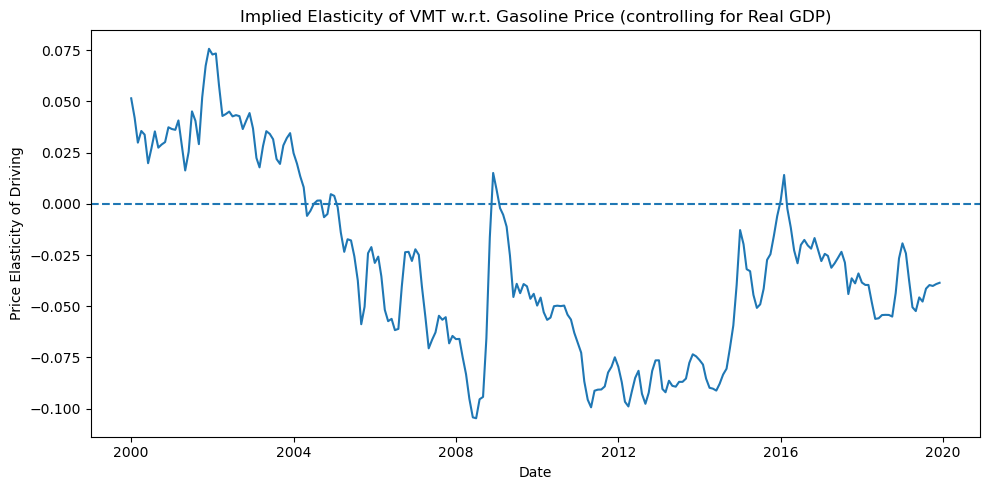

In [20]:
#Compute and plot elasticity
b0, b1, b2, b3 = model_gdp.params

df["elasticity"] = b1 + 2 * b2 * df["logP"]
print("\nMean elasticity over time (with GDP control):")
print(df["elasticity"].mean())

plt.figure(figsize=(10, 5))
plt.plot(df["observation_date"], df["elasticity"])
plt.axhline(0, linestyle="--")
plt.xlabel("Date")
plt.ylabel("Price Elasticity of Driving")
plt.title("Implied Elasticity of VMT w.r.t. Gasoline Price (controlling for Real GDP)")
plt.tight_layout()
plt.show()